# Hyperparameter Tuning with Grid Search and Randomized Search

Dataset: Breast Cancer Wisconsin (Diagnostic), bundled with scikit-learn. Each row is a tumor described by 30 numeric measurements computed from a digitized image of a fine needle aspirate. The task is to classify a tumor as malignant or benign.

Model: `RandomForestClassifier`. It has several hyperparameters that change its behavior, and it needs no feature scaling, so there is no preprocessing step that could leak information between splits.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, get_scorer)

RANDOM_STATE = 42

## 1. Load the data

In scikit-learn the target is coded `0 = malignant` and `1 = benign`. We flip it so that **malignant is the positive class (1)**. This way metrics such as recall answer a meaningful question: what share of malignant tumors did the model find?

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

df["malignant"] = (df["target"] == 0).astype(int)
df = df.drop(columns="target")

print(df.shape)
df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Structural checks

These checks only look at the shape and quality of the data. No statistic computed here is used to make a modeling decision.

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print()
print(df.dtypes.value_counts())
print()

counts = df["malignant"].value_counts().rename({0: "benign", 1: "malignant"})
print(pd.DataFrame({"count": counts, "share": (counts / len(df)).round(3)}))

Missing values: 0
Duplicated rows: 0

float64    30
int64       1
Name: count, dtype: int64

           count  share
malignant              
benign       357  0.627
malignant    212  0.373


## 3. Train / validation / test split

The data is split **before** any exploration that could influence modeling choices.

| Split | Share | Purpose |
|---|---|---|
| Train | 60% | Fit models. Cross-validation for tuning happens inside this set only. |
| Validation | 20% | Compare the best model found by Grid Search with the best model found by Randomized Search. |
| Test | 20% | Touched once, at the very end, to report the final performance. |

`stratify` keeps the malignant share the same in every split. Because Random Forest needs no scaling or imputation, no step is fitted on data outside the training set. If a scaler were needed, it would have to live inside a `Pipeline` so that cross-validation fits it on each training fold only.

In [4]:
X = df.drop(columns="malignant")
y = df["malignant"]

# Step 1: hold out the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Step 2: split the rest into train and validation (0.25 of 80% = 20% of the total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE
)

pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    "malignant share": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"]).round(3)

,rows,malignant share
train,341,0.372
validation,114,0.377
test,114,0.368


## 4. Exploration (training set only)

In [5]:
train_df = X_train.assign(malignant=y_train)
X_train.iloc[:, :5].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean radius,341.0,14.16,3.60,6.98,11.67,13.34,16.14,27.42
mean texture,341.0,19.43,4.36,9.71,16.39,18.90,21.87,39.28
mean perimeter,341.0,92.17,24.86,43.79,74.68,86.10,105.80,186.90
mean area,341.0,659.69,360.07,143.50,417.20,551.10,809.80,2501.00
mean smoothness,341.0,0.10,0.01,0.06,0.08,0.10,0.10,0.16


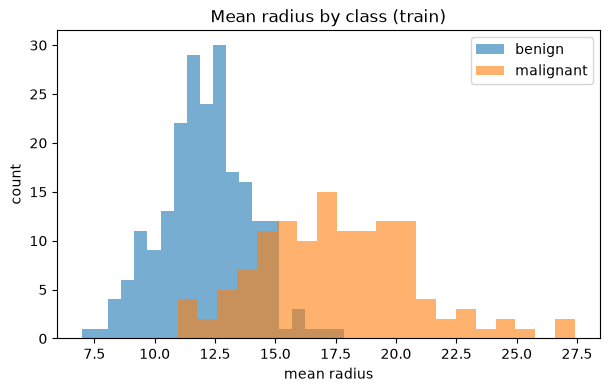

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, name in [(0, "benign"), (1, "malignant")]:
    ax.hist(train_df.loc[train_df["malignant"] == label, "mean radius"],
            bins=20, alpha=0.6, label=name)
ax.set_xlabel("mean radius")
ax.set_ylabel("count")
ax.set_title("Mean radius by class (train)")
ax.legend()
plt.show()

## 5. Baseline

A Random Forest with default hyperparameters, evaluated on the validation set. Tuning should be judged against this number.

In [7]:
baseline = RandomForestClassifier(random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)

val_pred = baseline.predict(X_val)
print("Baseline validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Baseline validation F1:      ", round(f1_score(y_val, val_pred), 4))

Baseline validation accuracy: 0.9737
Baseline validation F1:       0.9647


## 6. Choosing what to tune and how to score

Common `RandomForestClassifier` hyperparameters:

| Hyperparameter | Meaning |
|---|---|
| `n_estimators` | Number of trees in the forest. |
| `max_depth` | Maximum depth of each tree. `None` means trees grow until leaves are pure. |
| `min_samples_split` | Minimum samples a node needs to be split. |
| `min_samples_leaf` | Minimum samples required in a leaf. |
| `max_features` | Number of features considered at each split: `"sqrt"`, `"log2"`, or `None` (all). |
| `criterion` | Split quality measure: `"gini"`, `"entropy"`, `"log_loss"`. |

Scoring options for `scoring=`: `"accuracy"`, `"precision"`, `"recall"`, `"f1"`, `"roc_auc"`. Malignant is the positive class, so `"recall"` is the share of malignant tumors detected and `"precision"` is the share of predicted malignant tumors that really are malignant. The classes are imbalanced (about 37% malignant), which is one reason accuracy alone can be misleading.

In [8]:
# TODO 1: choose the metric used to rank models in both searches
scoring = "f1"

## 7. Grid Search

Number of combinations = k1 x k2 x ... x kn, where ki is the number of values listed for hyperparameter i. Total models trained = combinations x number of CV folds.

In [9]:
# TODO 2: define param_grid with at least 3 hyperparameters and 2 to 4 values each.
# Keys are hyperparameter names (strings), values are lists.
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 2],
}

In [10]:
# TODO 3: create the GridSearchCV object
#   estimator: RandomForestClassifier(random_state=RANDOM_STATE)
#   param_grid, scoring: the ones defined above
#   cv: 5-fold cross-validation
#   n_jobs: use all CPU cores
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring=scoring,
    cv=5,
    n_jobs=-1,
)

In [11]:
start = time.perf_counter()

# TODO 4: fit the grid search on the TRAINING set only
grid_search.fit(X_train, y_train)

grid_time = time.perf_counter() - start
print(f"Grid Search finished in {grid_time:.1f} s")

Grid Search finished in 20.6 s


In [12]:
# TODO 5: count the models
#   n_combinations: number of hyperparameter combinations that were tried
#   (hint: the number of entries in grid_search.cv_results_["params"])
#   total_fits: combinations x number of CV folds
n_folds = 5
n_combinations = len(grid_search.cv_results_["params"])
total_fits = n_combinations * n_folds

print("Combinations tried:", n_combinations)
print("CV folds:", n_folds)
print("Models trained during the search:", total_fits)

Combinations tried: 8
CV folds: 5
Models trained during the search: 40


In [13]:
# Check against the formula k1 x k2 x ... x kn
expected = int(np.prod([len(values) for values in param_grid.values()]))
print("Matches the formula:", n_combinations == expected)

Matches the formula: True


In [14]:
# TODO 6: print the best hyperparameters and the best cross-validation score
print("Best Grid Search hyperparameters:", grid_search.best_params_)
print(f"Best Grid Search CV {scoring}: {grid_search.best_score_:.4f}")

Best Grid Search hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best Grid Search CV f1: 0.9355


In [15]:
pd.DataFrame(grid_search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score").head(5)

,params,mean_test_score,std_test_score,rank_test_score
0,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.935500,0.034258,1
4,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.935500,0.034258,1
5,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.931729,0.029865,3
1,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.931729,0.029865,3
6,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.927982,0.032775,5


## 8. Randomized Search

Instead of trying every combination, Randomized Search samples `n_iter` combinations. Values can be lists (sampled uniformly) or distributions such as `scipy.stats.randint(low, high)`, which draws an integer in `[low, high)`. Total models trained = `n_iter` x number of CV folds, regardless of how large the search space is.

In [16]:
# TODO 7: define param_distributions with at least 3 hyperparameters.
# Use randint(low, high) for integer ranges and lists for categorical values.
# Use a wider range than in the grid.
param_distributions = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 11),
    "max_features": ["sqrt", "log2", None],
}

# TODO 8: choose n_iter (smaller than the number of combinations in the grid)
n_iter = 5

In [17]:
# TODO 9: create the RandomizedSearchCV object
#   estimator, scoring and cv as before, n_jobs=-1
#   param_distributions and n_iter from above
#   random_state=RANDOM_STATE so the sampling is reproducible
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=n_iter,
    scoring=scoring,
    cv=5,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

In [18]:
start = time.perf_counter()

# TODO 10: fit the randomized search on the TRAINING set only
random_search.fit(X_train, y_train)

random_time = time.perf_counter() - start
print(f"Randomized Search finished in {random_time:.1f} s")

Randomized Search finished in 3.8 s


In [19]:
# TODO 11: count the models for the randomized search
random_combinations = len(random_search.cv_results_["params"])
random_total_fits = random_combinations * n_folds

print("Combinations sampled:", random_combinations)
print("CV folds:", n_folds)
print("Models trained during the search:", random_total_fits)

Combinations sampled: 5
CV folds: 5
Models trained during the search: 25


In [20]:
# TODO 12: print the best hyperparameters and the best cross-validation score
print("Best Randomized Search hyperparameters:", random_search.best_params_)
print(f"Best Randomized Search CV {scoring}: {random_search.best_score_:.4f}")


Best Randomized Search hyperparameters: {'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 5, 'min_samples_split': 3, 'n_estimators': 443}
Best Randomized Search CV f1: 0.9283


In [21]:
pd.DataFrame(random_search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score").head(5)

,params,mean_test_score,std_test_score,rank_test_score
2,"{'max_depth': 10, 'max_features': 'log2', 'min...",0.928298,0.027503,1
4,"{'max_depth': 15, 'max_features': 'sqrt', 'min...",0.928298,0.027503,1
3,"{'max_depth': 15, 'max_features': 'log2', 'min...",0.924063,0.026816,3
0,"{'max_depth': 15, 'max_features': 'sqrt', 'min...",0.915396,0.024032,4
1,"{'max_depth': 10, 'max_features': None, 'min_s...",0.912405,0.020955,5


## 9. Grid Search vs Randomized Search

In [22]:
pd.DataFrame({
    "Grid Search": {
        "combinations": n_combinations,
        "models trained": total_fits,
        "time (s)": round(grid_time, 1),
        f"best CV {scoring}": round(grid_search.best_score_, 4),
    },
    "Randomized Search": {
        "combinations": random_combinations,
        "models trained": random_total_fits,
        "time (s)": round(random_time, 1),
        f"best CV {scoring}": round(random_search.best_score_, 4),
    },
}, dtype=object)

,Grid Search,Randomized Search
combinations,8.0,5.0
models trained,40.0,25.0
time (s),20.6,3.8
best CV f1,0.9355,0.9283


## 10. Choosing the best model on the validation set

Both searches only used the training set. The validation set, which neither search has seen, decides which of the two winners to keep. With about 114 validation rows, very small differences are noise.

In [23]:
scorer = get_scorer(scoring)

val_grid = scorer(grid_search.best_estimator_, X_val, y_val)
val_random = scorer(random_search.best_estimator_, X_val, y_val)

print(f"Validation {scoring}, Grid Search winner:       {val_grid:.4f}")
print(f"Validation {scoring}, Randomized Search winner: {val_random:.4f}")

Validation f1, Grid Search winner:       0.9647
Validation f1, Randomized Search winner: 0.9647


In [24]:
# TODO 13: store the hyperparameters of the winner (higher validation score)
best_params = (
    grid_search.best_params_ if val_grid >= val_random
    else random_search.best_params_
)
print("Selected hyperparameters:", best_params)

Selected hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}


## 11. Final model and test evaluation

Validation data is no longer needed for decisions, so the final model is trained on train + validation (80% of the data) and evaluated once on the untouched test set.

In [25]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# TODO 14: create the final model with the selected hyperparameters
#   (hint: RandomForestClassifier(**best_params, random_state=RANDOM_STATE))
final_model = RandomForestClassifier(**best_params, random_state=RANDOM_STATE)

# TODO 15: fit the final model on train + validation
final_model.fit(X_train_val, y_train_val)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [26]:
# TODO 16: predict on the test set
y_test_pred = final_model.predict(X_test)

Test f1: 0.95

              precision    recall  f1-score   support

      benign       0.95      1.00      0.97        72
   malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



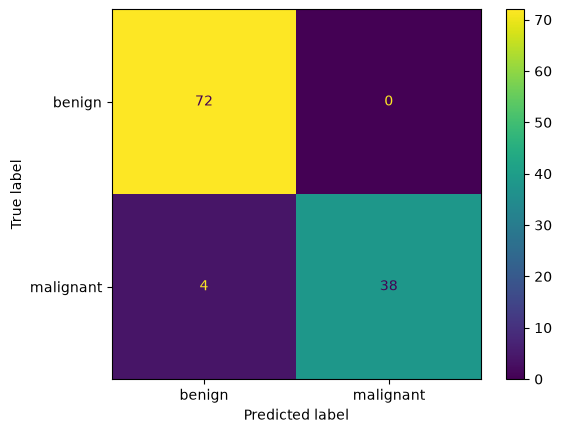

In [27]:
print(f"Test {scoring}:", round(scorer(final_model, X_test, y_test), 4))
print()
print(classification_report(y_test, y_test_pred, target_names=["benign", "malignant"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["benign", "malignant"]
)
plt.show()

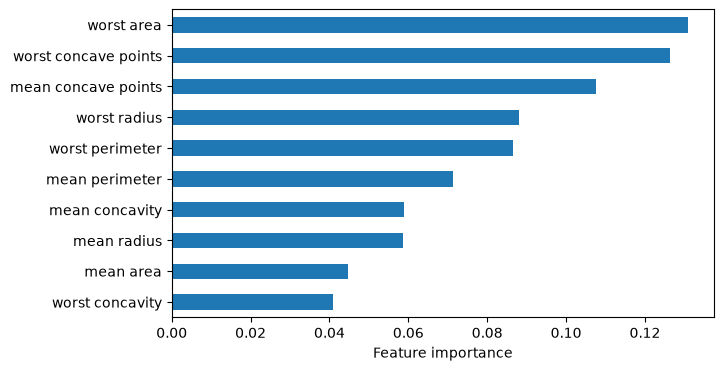

In [28]:
importances = pd.Series(final_model.feature_importances_, index=X.columns)
importances.sort_values().tail(10).plot(kind="barh", figsize=(7, 4))
plt.xlabel("Feature importance")
plt.show()

## 12. Report

Run the cell below and send its output.

In [29]:
print("Scoring metric:           ", scoring)
print("Grid Search     :", n_combinations, "combinations,", total_fits, "models, best CV score", round(grid_search.best_score_, 4))
print("Randomized Search:", random_combinations, "combinations,", random_total_fits, "models, best CV score", round(random_search.best_score_, 4))
print("Selected model   :", best_params)
print("Test score       :", round(scorer(final_model, X_test, y_test), 4))

Scoring metric:            f1
Grid Search     : 8 combinations, 40 models, best CV score 0.9355
Randomized Search: 5 combinations, 25 models, best CV score 0.9283
Selected model   : {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Test score       : 0.95
